# 06 — Final comparative analysis

This notebook brings together all the models of the project: the clean baseline, the poisoned models at 1%, 3%, 5% and 10% of the Stop training images, and the repaired models. It adds:

- a **poisoning rate study** (two new poisoned models at 1% and 3%, same nested selection and pipeline);
- **confusion matrices** of the clean, poisoned and repaired models;
- one **post-hoc** repair (union of the ART and centroid suspects), clearly separated from the a-priori results.

Every number comes from `src/` functions and is saved in `results/`. Set `FORCE_RETRAIN = True` to retrain the 4 models trained here even if checkpoints with the same configuration exist.

In [1]:
FORCE_RETRAIN = False

In [2]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")

import numpy as np
import pandas as pd

from src.attack import run_name_for_rate
from src.config import load_config, resolve_path
from src.data import GTSRB_CLASS_NAMES, load_gtsrb, load_train_groups, train_val_indices
from src.detection import run_detection
from src.evaluate import top_confusions
from src.experiment import (
    detection_rows,
    evaluate_with_attack,
    final_summary_row,
    load_poisoned_run,
    repair_run,
    score_detection,
    train_poisoned_run,
)
from src.plots import (
    plot_confusion_matrices,
    plot_poison_left_vs_asr,
    plot_rate_vs_asr,
    plot_rate_vs_detection,
    plot_triggered_source_predictions,
)
from src.remediation import UNION
from src.train import load_model
from src.utils import load_json, markdown_table, save_env_info, save_json, set_seed

cfg = load_config()
set_seed(cfg["seed"])
save_env_info(resolve_path(cfg, "env_info"))
figures_dir, metrics_dir = resolve_path(cfg, "figures_dir"), resolve_path(cfg, "metrics_dir")
source, target = cfg["backdoor"]["source_class"], cfg["backdoor"]["target_class"]
study_rates = cfg["analysis"]["study_poison_rates"]
repaired_rates = [cfg["backdoor"]["poison_rate"]] + cfg["attack"]["extra_poison_rates"]
new_rates = [r for r in study_rates if r not in repaired_rates]
A_PRIORI = {"clustering": "Activation clustering (ours)", "art": "ART ActivationDefence", "centroid": "Distance to centroid"}

INFO art.config: set ART_DATA_PATH to /home/mdev/.art/data


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/env_info.json


In [3]:
x_full, y_full, x_test, y_test = load_gtsrb(cfg)
groups_full = load_train_groups(cfg)
train_idx, val_idx = train_val_indices(y_full, groups_full, cfg["data"]["val_ratio"], cfg["seed"])
x_train, y_train, groups_train = x_full[train_idx], y_full[train_idx], groups_full[train_idx]
x_val, y_val = x_full[val_idx], y_full[val_idx]
print(f"train {len(y_train)}, val {len(y_val)}, test {len(y_test)}; rates trained here: {new_rates}")

INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


INFO src.data: Loading GTSRB from cache /home/mdev/Dev/school/SD/gtsrb-data-poisoning/data/processed


train 23880, val 2760, test 12630; rates trained here: [0.01, 0.03]


## 1. Two more poisoned models: 1% and 3%

Same attack, same trigger, same training pipeline as notebook 03, only the number of poisoned Stop images changes. The selections are nested: the 1% images are among the 3% ones, which are among the 5% and 10% ones. No detection parameter changes and no remediation is run for these two rates.

In [4]:
for rate in new_rates:
    run = train_poisoned_run(x_train, y_train, groups_train, x_val, y_val, x_test, y_test, cfg, rate,
                             force_retrain=FORCE_RETRAIN)
    history = run["history"]
    print(f"{run_name_for_rate(rate)}: {run['record']['n_poisoned']} poisoned images, best epoch {history['best_epoch']}, "
          f"training time {history['total_time_s'] / 60:.1f} min")

records = {rate: load_json(metrics_dir / f"{run_name_for_rate(rate)}_poison_record.json") for rate in study_rates}
print("nested selections:", all(set(records[a]["indices"]) <= set(records[b]["indices"])
                                for a, b in zip(study_rates, study_rates[1:])))

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r01_poison_record.json


INFO src.train: Loaded poisoned_r01 from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/poisoned_r01.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r01_test_metrics.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r03_poison_record.json


poisoned_r01: 5 poisoned images, best epoch 29, training time 28.4 min


INFO src.train: Loaded poisoned_r03 from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/poisoned_r03.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/poisoned_r03_test_metrics.json


poisoned_r03: 14 poisoned images, best epoch 23, training time 22.6 min
nested selections: True


## 2. Post-hoc repair: union of the ART and centroid suspects

**POST-HOC.** Notebook 05 showed that each a-priori suspect list repairs only one rate: ART at 10%, distance to centroid at 5%. The natural recommendation is to remove the **union** of both lists. This choice was made **after seeing the remediation results**, so it is a recommendation to confirm on other runs, not an a-priori result. It is trained with exactly the same pipeline (`repair_run`) and labelled `(post-hoc)` in every table and figure.

In [5]:
for rate in repaired_rates:
    name, _, x_p, y_p, record, rate_cfg = load_poisoned_run(x_train, y_train, cfg, rate)
    run_name = f"repaired_{name.removeprefix('poisoned_')}_{UNION}"
    run = repair_run(x_p, y_p, x_val, y_val, x_test, y_test, rate_cfg, run_name, UNION, record,
                     force_retrain=FORCE_RETRAIN)
    print(f"{run_name} (post-hoc): removed {run['removal']['n_removed']}, "
          f"training time {run['history']['total_time_s'] / 60:.1f} min")

INFO src.train: Loaded repaired_r05_union from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/repaired_r05_union.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r05_union_test_metrics.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r05_union_removal.json


repaired_r05_union (post-hoc): removed 1227, training time 11.2 min


INFO src.train: Loaded repaired_r10_union from /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/models/repaired_r10_union.pt (training config unchanged)


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r10_union_test_metrics.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/repaired_r10_union_removal.json


repaired_r10_union (post-hoc): removed 1237, training time 22.8 min


## 3. Final summary of all models

Every model is evaluated on the same clean test set with the same functions. `n_removed` is the number of training images removed, `n_poison_remaining` the number of poisoned images left in its training set (computed with the poison record, for evaluation only). Oracle rows are a **reference upper bound** (they use the true poison indices); union rows are **post-hoc**.

In [6]:
LABELS = {"oracle": " (upper bound)", UNION: " (post-hoc)"}
baseline_metrics = evaluate_with_attack(load_model(resolve_path(cfg, "models_dir") / "baseline.pt", cfg), x_test, y_test, cfg)

final = [{**final_summary_row(cfg, "baseline", 0, baseline_metrics), "rate": 0.0}]
for rate in study_rates:
    name = run_name_for_rate(rate)
    final.append({**final_summary_row(cfg, name, records[rate]["n_poisoned"]), "rate": rate})
for rate in repaired_rates:
    name = run_name_for_rate(rate)
    for method in cfg["remediation"]["suspect_lists"] + [UNION]:
        run_name = f"repaired_{name.removeprefix('poisoned_')}_{method}"
        row = final_summary_row(cfg, run_name, records[rate]["n_poisoned"])
        final.append({**row, "model": run_name + LABELS.get(method, ""), "rate": rate})

columns = ["model", "rate", "clean_acc", "macro_f1", "stop_acc", "asr", "n_removed", "n_poison_remaining"]
save_json({"note": "oracle rows: reference upper bound; union rows: post-hoc", "rows": final},
          metrics_dir / "final_summary.json")
resolve_path(cfg, "final_summary_md").write_text(markdown_table(final, columns))
pd.DataFrame(final)[columns].set_index("model").round(4)

INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/final_summary.json


,rate,clean_acc,macro_f1,stop_acc,asr,n_removed,n_poison_remaining
model,,,,,,,
baseline,0.00,0.9736,0.9556,1.0000,0.0000,0,0
poisoned_r01,0.01,0.9844,0.9767,1.0000,0.0741,0,5
poisoned_r03,0.03,0.9827,0.9689,1.0000,0.8704,0,14
poisoned_r05,0.05,0.9868,0.9795,0.9963,0.9405,0,24
poisoned_r10,0.10,0.9803,0.9656,0.9963,0.9294,0,48
repaired_r05_art,0.05,0.9677,0.9519,1.0000,0.8852,1013,24
repaired_r05_centroid,0.05,0.9770,0.9572,1.0000,0.0000,260,9
repaired_r05_oracle (upper bound),0.05,0.9726,0.9619,1.0000,0.0000,24,0
repaired_r05_union (post-hoc),0.05,0.9744,0.9612,1.0000,0.0000,1227,9


## 4. Poisoning rate study

### 4.1 Attack strength

Clean accuracy and ASR of each poisoned model against the number of poisoned training images (0 = clean baseline).

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/rate_vs_asr.png


,n_poisoned,asr,clean_acc,share_of_train,stop_acc
rate,,,,,
0.00,0,0.0000,0.9736,NaN,NaN
0.01,5,0.0741,0.9844,0.0002,1.0000
0.03,14,0.8704,0.9827,0.0006,1.0000
0.05,24,0.9405,0.9868,0.0010,0.9963
0.10,48,0.9294,0.9803,0.0020,0.9963


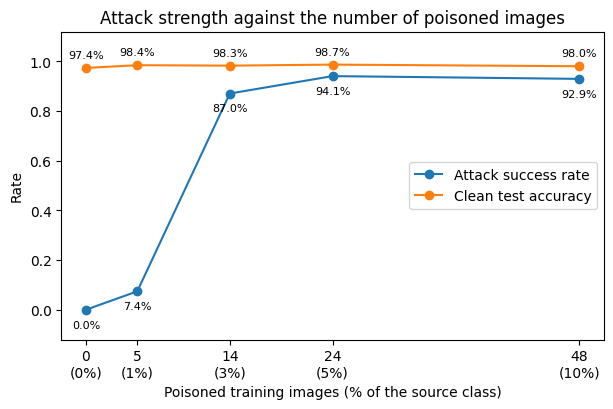

In [7]:
by_model = {row["model"]: row for row in final}
rate_rows = [{"rate": 0.0, "n_poisoned": 0, "asr": by_model["baseline"]["asr"], "clean_acc": by_model["baseline"]["clean_acc"]}]
rate_rows += [
    {"rate": rate, "n_poisoned": records[rate]["n_poisoned"],
     "share_of_train": records[rate]["n_poisoned"] / len(y_train),
     **{k: by_model[run_name_for_rate(rate)][k] for k in ("asr", "clean_acc", "stop_acc")}}
    for rate in study_rates
]
plot_rate_vs_asr(rate_rows, figures_dir / "rate_vs_asr.png")
pd.DataFrame(rate_rows).set_index("rate").round(4)

### 4.2 Detection quality for every rate

The three a-priori methods with their fixed parameters (notebook 04), run on the saved poisoned models; no retraining. The 5% and 10% scores are read from the files saved by notebook 04.

INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_clustering_poisoned_r01.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_poisoned_r01.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_centroid_poisoned_r01.json


INFO art.estimators.classification.pytorch: Inferred 4 hidden layers on PyTorch classifier.


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_clustering_poisoned_r03.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_art_poisoned_r03.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/detection_centroid_poisoned_r03.json


INFO src.utils: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/metrics/rate_study.json


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/rate_vs_detection.png


n_flagged  tp    fp  precision  recall  \
rate method                                                                 
0.01 Activation clustering (ours)       1511   5  1506      0.003   1.000   
     ART ActivationDefence               732   0   732      0.000   0.000   
     Distance to centroid                304   5   299      0.016   1.000   
0.03 Activation clustering (ours)        591   0   591      0.000   0.000   
     ART ActivationDefence               640   0   640      0.000   0.000   
     Distance to centroid                222   7   215      0.032   0.500   
0.05 Activation clustering (ours)       1142   0  1142      0.000   0.000   
     ART ActivationDefence              1013   0  1013      0.000   0.000   
     Distance to centroid                260  15   245      0.058   0.625   
0.10 Activation clustering (ours)       1386  48  1338      0.035   1.000   
     ART ActivationDefence              1019  48   971      0.047   1.000   
     Distance to centroid                270  12   258      0.044   0.250   

                                      f1  
rate method                               
0.01 Activation clustering (ours)  0.007  
     ART ActivationDefence         0.000  
     Distance to centroid          0.032  
0.03 Activation clustering (ours)  0.000  
     ART ActivationDefence         0.000  
     Distance to centroid          0.059  
0.05 Activation clustering (ours)  0.000  
     ART ActivationDefence         0.000  
     Distance to centroid          0.106  
0.10 Activation clustering (ours)  0.067  
     ART ActivationDefence         0.090  
     Distance to centroid          0.075

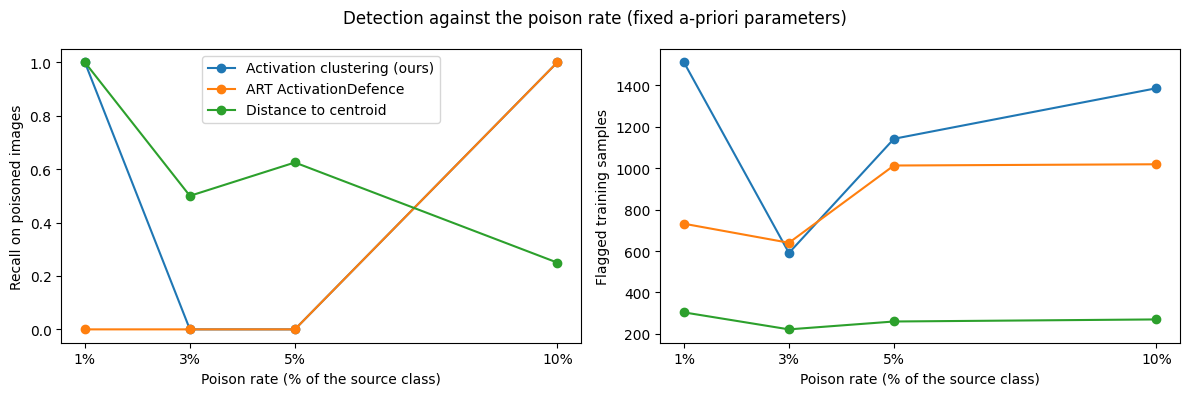

In [8]:
detection = []
for rate in study_rates:
    name, model, x_p, y_p, record, rate_cfg = load_poisoned_run(x_train, y_train, cfg, rate)
    if rate in new_rates:
        suspects = run_detection(model, x_p, y_p, x_val, y_val, rate_cfg)["suspects"]
        scores = score_detection(name, {m: suspects[m] for m in A_PRIORI}, y_p, record, rate_cfg)
    else:
        scores = {m: load_json(metrics_dir / f"detection_{m}_{name}.json") for m in A_PRIORI}
    detection += [{**row, "rate": rate, "method": A_PRIORI[row["method"]]} for row in detection_rows(name, scores)]

save_json({"parameters": cfg["detection"], "attack": rate_rows, "detection": detection}, metrics_dir / "rate_study.json")
plot_rate_vs_detection(detection, figures_dir / "rate_vs_detection.png")
pd.DataFrame(detection).set_index(["rate", "method"])[["n_flagged", "tp", "fp", "precision", "recall", "f1"]].round(3)

**Attack.** Few images are enough. 5 poisoned Stop images (1% of the source class) give an ASR of 7.4% (20 / 270). 14 images (3%) already give 87.0%, and 24 images (5%) give 94.1%. 14 images are 0.06% of the 23,880 training images. Clean accuracy stays between 98.0% and 98.7% for all poisoned models (baseline 97.4%), so it gives no warning: one training run per model, differences of about 1 point are within run-to-run variation.

**Detection.** No method works at all rates, and precision stays below 6% everywhere (hundreds of clean images flagged for a handful of poisoned ones):

- at 1%, activation clustering and distance to centroid find all 5 poisoned images (recall 1.0, with 1,506 and 299 false positives). At this rate the backdoor is barely learned (ASR 7.4%), so the poisoned images likely still look like Stop signs inside the Speed limit 80 class and stand out;
- at 3% and 5%, when the backdoor is learned, clustering and ART find none; distance to centroid finds 7 / 14 and 15 / 24;
- at 10%, clustering and ART find all 48 (the poisoned images are numerous enough to form their own cluster), while distance to centroid finds only 12 / 48.

So "more poison is easier to detect" holds for the clustering methods between 5% and 10%, but the range that matters most for a defender, a few images that are enough to install the backdoor (3% to 5%), is exactly where clustering and ART fail.

## 5. Confusion matrices and the triggered Stop images

For each rate, three models: the clean baseline, the poisoned model, and the a-priori repair that removes the backdoor at that rate (distance to centroid at 5%, ART at 10%). The confusion matrices use the **clean** test set; the bar chart uses the **triggered** Stop test images (the same eligible images as the ASR).

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/confusion_matrices_r05.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/triggered_stop_r05.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/confusion_matrices_r10.png


INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/triggered_stop_r10.png


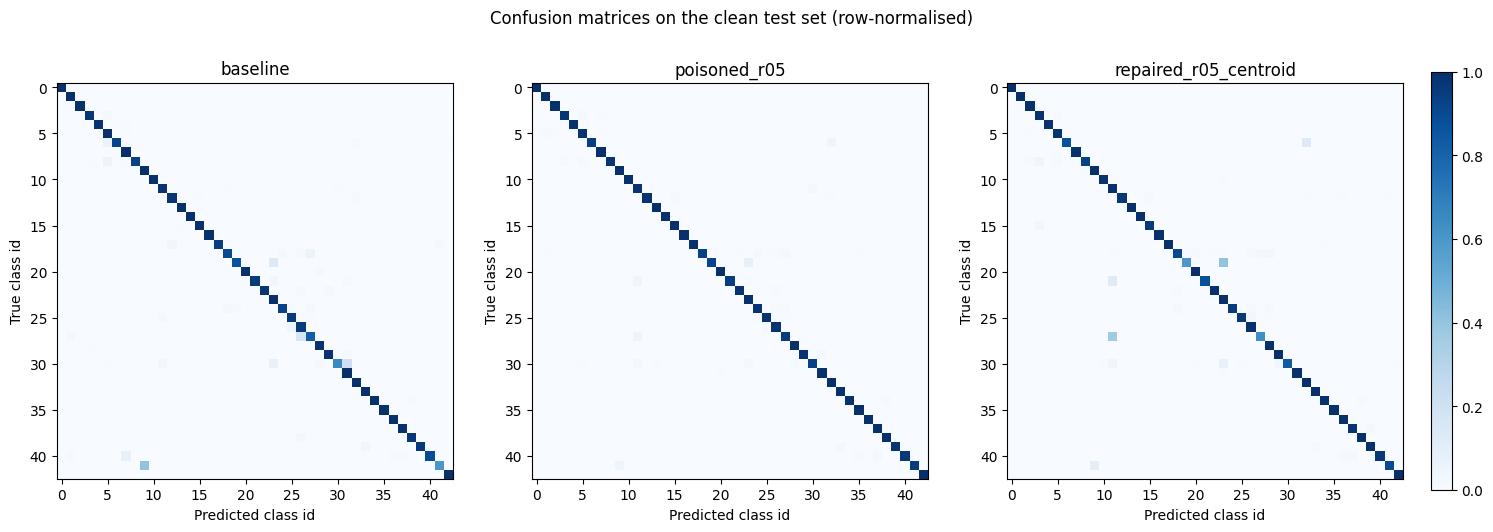

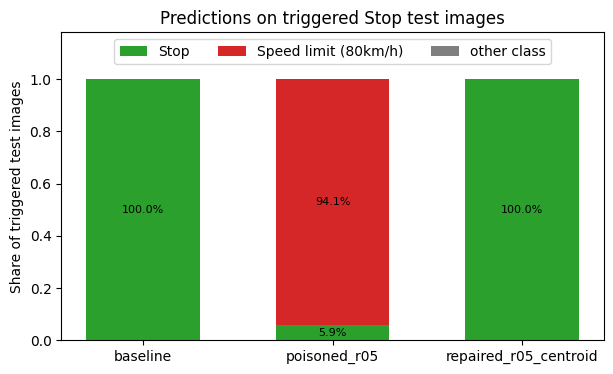

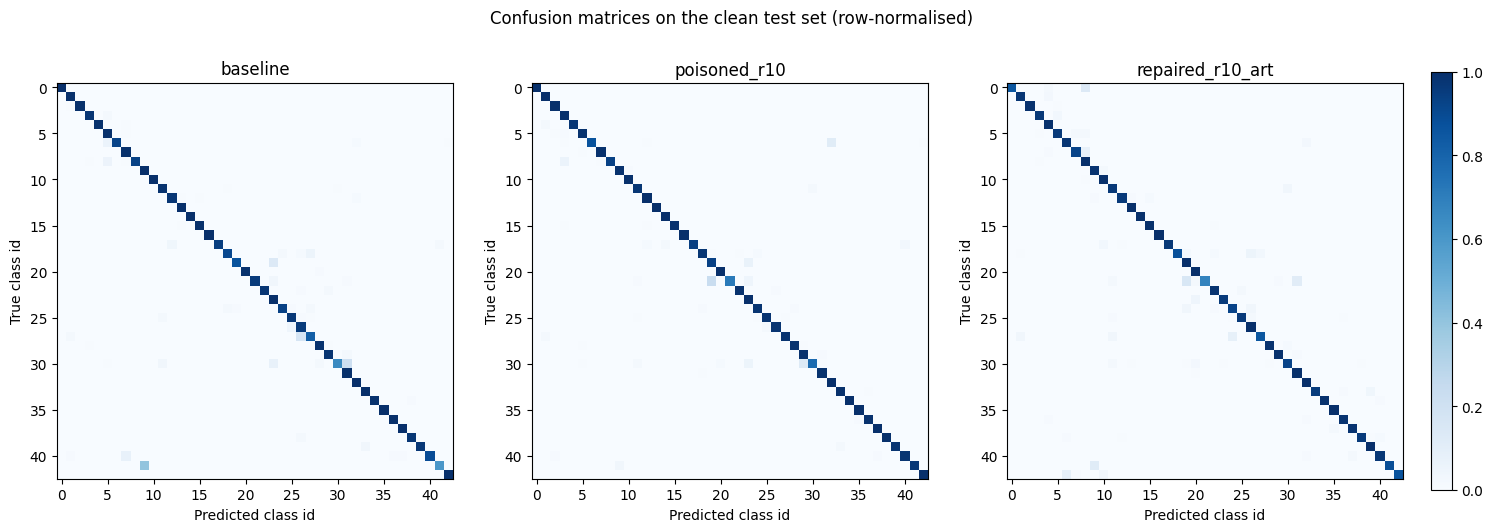

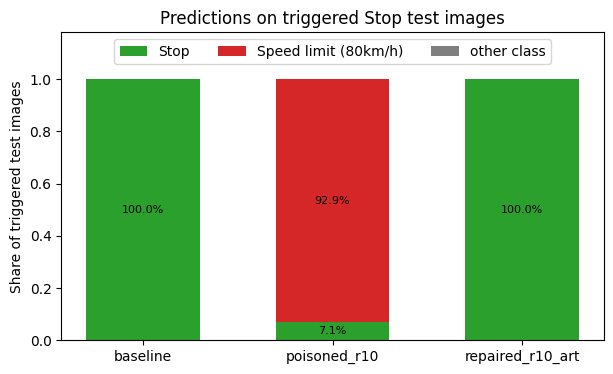

In [9]:
comparisons = {"r05": "repaired_r05_centroid", "r10": "repaired_r10_art"}
all_metrics = {"baseline": baseline_metrics}
for tag, repaired_name in comparisons.items():
    names = ["baseline", f"poisoned_{tag}", repaired_name]
    for name in names[1:]:
        all_metrics[name] = load_json(metrics_dir / f"{name}_test_metrics.json")
    plot_confusion_matrices({n: all_metrics[n]["confusion_matrix"] for n in names}, figures_dir / f"confusion_matrices_{tag}.png")
    plot_triggered_source_predictions(
        {n: all_metrics[n]["asr"]["triggered_predictions"] for n in names}, source, target, GTSRB_CLASS_NAMES,
        figures_dir / f"triggered_stop_{tag}.png",
    )

Largest confusions on the clean test set (true class -> predicted class, number of test images):

In [10]:
pd.DataFrame({
    name: [f"{c['true']} -> {c['predicted']}: {c['count']}" for c in top_confusions(np.array(m["confusion_matrix"]), k=5)]
    for name, m in all_metrics.items()
}, index=[f"#{i}" for i in range(1, 6)])

,baseline,poisoned_r05,repaired_r05_centroid,poisoned_r10,repaired_r10_art
#1,30 -> 31: 32,3 -> 5: 9,19 -> 23: 24,8 -> 3: 27,7 -> 8: 32
#2,8 -> 5: 25,18 -> 27: 9,27 -> 11: 22,21 -> 19: 21,18 -> 26: 20
#3,41 -> 9: 24,5 -> 1: 8,6 -> 32: 19,30 -> 29: 19,1 -> 4: 17
#4,18 -> 27: 20,18 -> 24: 7,8 -> 3: 18,6 -> 32: 17,3 -> 5: 14
#5,17 -> 12: 13,6 -> 32: 7,25 -> 26: 15,4 -> 1: 11,21 -> 19: 14


In [11]:
pd.DataFrame(
    {c: GTSRB_CLASS_NAMES[c] for c in sorted({c[k] for m in all_metrics.values()
                                                 for c in top_confusions(np.array(m["confusion_matrix"]), k=5)
                                                 for k in ("true", "predicted")})}.items(),
    columns=["class id", "name"],
).set_index("class id")

,name
class id,
1,Speed limit (30km/h)
3,Speed limit (60km/h)
4,Speed limit (70km/h)
5,Speed limit (80km/h)
6,End of speed limit (80km/h)
7,Speed limit (100km/h)
8,Speed limit (120km/h)
9,No passing
11,Right-of-way at next intersection


On the **clean** test set, the three matrices of each rate look alike: a strong diagonal with a few confusions between visually close signs (speed limits among themselves such as 8 -> 3 or 3 -> 5, warning triangles such as 18 -> 27 or 19 -> 23, end-of-restriction signs such as 6 -> 32 or 41 -> 9). The largest confusions are not the same from one model to the next: every model is a separate training run, and these errors move with the run. None of them involves the Stop class, whose clean accuracy is 99.3% to 100% for all five models; the backdoor is invisible on clean images.

The backdoor appears only **with the trigger**: on triggered Stop test images, the baseline still predicts Stop for 100% of them, the poisoned models predict Speed limit 80 for 94.1% (5%) and 92.9% (10%), and the repaired models are back to 100% Stop. Clean-test metrics alone cannot reveal a backdoor; it must be tested with the trigger, which a defender usually does not know.

## 6. Poison left vs ASR (all models)

Each point is one model: the number of poisoned images in its training set (after removal for the repaired models) and its ASR.

INFO src.plots: Saved /home/mdev/Dev/school/SD/gtsrb-data-poisoning/results/figures/poison_left_vs_asr.png


,n_poison_remaining,asr
model,,
baseline,0,0.0000
repaired_r05_oracle (upper bound),0,0.0000
repaired_r10_art,0,0.0000
repaired_r10_oracle (upper bound),0,0.0000
repaired_r10_union (post-hoc),0,0.0000
poisoned_r01,5,0.0741
repaired_r05_centroid,9,0.0000
repaired_r05_union (post-hoc),9,0.0000
poisoned_r03,14,0.8704


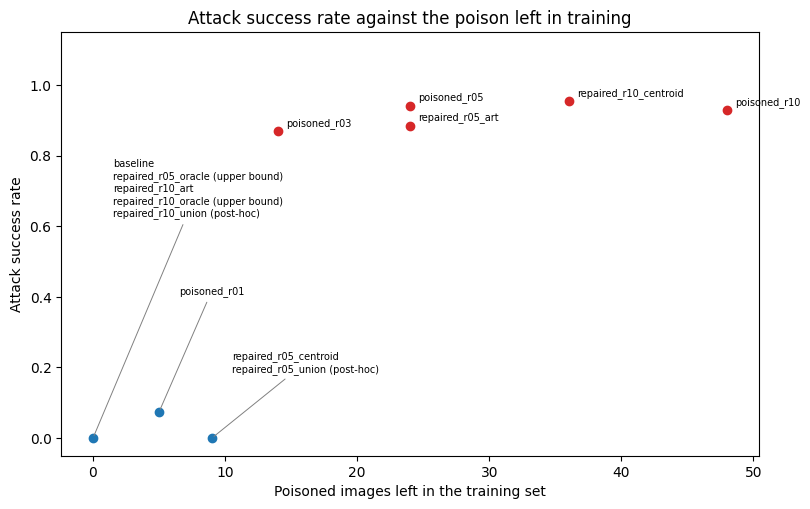

In [12]:
plot_poison_left_vs_asr(final, figures_dir / "poison_left_vs_asr.png")
pd.DataFrame(final).sort_values(["n_poison_remaining", "asr"])[["model", "n_poison_remaining", "asr"]].set_index("model").round(4)

The ASR depends mostly on how many poisoned images remain in training, whatever the way they were left there (attack at a low rate or incomplete removal). With 0 to 9 poisoned images left, the ASR is 0% to 7.4%; with 14 or more, it is 87% to 96%. On this one-seed data the transition lies between 9 and 14 images; its exact position is not measured.

For remediation this means a defence does not need to find every poisoned image, but it must leave fewer than about ten here. A detection with low precision is acceptable if the removal cost stays small: the union of the ART and centroid lists (**post-hoc**) removes 1,227 and 1,237 images (about 5% of the training set), brings the ASR to 0% at both 5% and 10%, and keeps clean accuracy at 97.4% and 98.2%. It was not tested at 3%, where its two lists would leave 7 of the 14 poisoned images (ART finds none, centroid 7), a number inside the uncertain transition zone.

## 7. Limits

- **One seed per model.** Each number comes from a single training run; differences of about 1 point of accuracy, and the exact ASR transition between 9 and 14 poisoned images, need several seeds to be confirmed.
- **One attack setting.** One trigger (white 4x4 square, bottom-right), one source/target pair (Stop -> Speed limit 80), dirty-label poisoning. Other triggers (blended, smaller, clean-label attacks) may behave very differently.
- **Small clean validation set per class.** The track-aware split keeps whole tracks in validation, so 23 of the 43 classes have only 30 validation images (one track); this limits the calibrated method and early stopping.
- **ART layer.** ART's ActivationDefence reads the last layer (logits) by default; it had to be pointed to the hidden layer `fc`. Results depend on that choice.
- **Method 4 failed.** The distance calibrated on clean validation data flagged 12.4% of the training set instead of about 1% (train/validation activation shift), so it was not used for remediation.
- **The union is post-hoc.** It was chosen after seeing the remediation results; its success at 5% and 10% must be confirmed on other runs and rates before being called a defence.
- **Detection precision is very low** (below 6% for every method and rate): a real pipeline would discard hundreds to thousands of clean images.

## 8. Prevention measures for a real ML pipeline

Detection after the fact was weak here, so most of the protection has to come before training:

- **Data provenance.** Know where every image and label comes from. Only 14 images were enough for an 87% ASR: one untrusted contributor can be enough.
- **Dataset integrity (hashes).** Hash the dataset files and record them with each training run, so a modified image or label is noticed. Our runs record a hash of the removed indices for the same reason (the retraining is tied to the exact data).
- **Validation and filtering of collected data.** Check labels against the image content (a Stop sign labelled Speed limit 80 is a label error a human or a second model can spot), and look for unusual patterns such as identical patches in the same place.
- **Monitoring of data distributions.** Watch class counts and activation statistics between dataset versions. The trigger did not change clean accuracy, so model metrics alone would not raise an alarm.
- **Traceability of the training pipeline.** Version data, configuration, code and checkpoints together (as `train_or_load` does with the config sections), so a suspect model can be traced back to its data and retrained without it.
- **Audits across the model lifecycle.** Test models with candidate triggers and on the classes that matter most (here Stop), before deployment and again after each retraining; a clean-test evaluation alone missed the backdoor.

## 9. Conclusion

A BadNets-style backdoor is cheap and silent on GTSRB: 14 poisoned Stop images (0.06% of the training set) give an 87% ASR, and 24 images give 94%, while clean accuracy stays at 98% or above, so ordinary evaluation does not reveal it. The three a-priori detection methods with fixed parameters never reach 6% precision, and none of them finds the poison at every rate: clustering and ART find all the poisoned images at 10% but none at 3% and 5%, while distance to centroid finds 50% to 100% of it at 1% to 5% but only a quarter at 10%. Remediation by removal and retraining works when it leaves fewer than about ten poisoned images: the oracle (reference upper bound), the centroid list at 5% and the ART list at 10% all bring the ASR to 0% with clean accuracy between 96.8% and 97.7%. The union of the ART and centroid lists, chosen **post-hoc**, repairs both 5% and 10% with clean accuracy of 97.4% and 98.2%, at the cost of removing about 5% of the training data; this is a recommendation to confirm, not an a-priori result. These results come from one seed per model and one trigger, so the general lesson is the order of magnitude rather than the exact numbers: detection based on activations alone is unreliable at low rates, and prevention (data provenance, integrity and validation of collected data) matters more than repair.